# E6 · Are the rules correct, and do guardrails matter? (live session)

PLAN §9, E6. Baseline: no guardrails. Stream C owns it. This notebook has four parts:

1. **Conflict check**: what the validator says about the shipped rule base.
2. **Scenario test cases**: hand-built members with the firings, allowed offers and blocked offers we expect
   (`tests/fixtures/rule_cases.yaml`, also run by `tests/test_rule_cases.py` as a regression test).
3. **Coverage on the 4,000 real members**: which rules fire, which never do, how often guardrails remove a playbook proposal.
4. **Plan value with vs without guardrails**: needs Stream B's optimiser; a marked stub at the end.

Everything is imported from `anchorai`; no rule logic is copied here. Nothing is written to the app DB or to Neo4j.
It reads the built data (`uv run anchorai data build`) and the cached KG facts (`uv run anchorai kg load`).

**Caveat (say it wherever these numbers are quoted).** The rule base is **hand-written by the team** and the thresholds
come from the training split of the real data (c_rules.ipynb). The scenario test cases test that the rules do what we
*meant*, not that what we meant is *right*; and because we wrote both, they are optimistic. `trend_ratio` and
`avg_class_frequency_current_month` are suspect features (`results/a_leakage.md`), so rules built on them (D01, D03, P01)
select members partly on information that may come from the churn month. `lost_anchor_instructor`, `class_cancelled`
and `days_since_last_contact` come from the **synthetic scenario layer**, so how often they fire reflects our simulator,
not real gyms.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from anchorai.reasoning.engine import load_rule_files, run
from anchorai.reasoning.facts import KNOWN_FACTS
from anchorai.reasoning.service import all_facts
from anchorai.reasoning.validate import validate
from anchorai.scenario.offers import OFFER_CATALOG
from anchorai.schemas import Channel

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

rules = load_rule_files()
by_id = {r.id: r for r in rules}
offers = [o["offer_id"] for o in OFFER_CATALOG]
print(len(rules), "rules:", pd.Series([r.kind for r in rules]).value_counts().to_dict())

20 rules: {'derive': 8, 'playbook': 8, 'guardrail': 4}


## 1. Conflict check

`validate` flags duplicate ids, unknown facts/offers/channels, unreachable conditions and derive rules that contradict
each other. Expect an empty table for the shipped rule base. A non-empty one is a finding.

In [2]:
issues = validate(rules, KNOWN_FACTS, offers, [c.value for c in Channel])
issues_table = pd.DataFrame([i.model_dump() for i in issues], columns=["rule_id", "severity", "message"])
issues_table.to_csv(RES / "e6_validation_issues.csv", index=False)
print(len(issues), "issues")
issues_table

0 issues


,rule_id,severity,message


## 2. Scenario test cases

Each case is a fact set built by hand (base member + overrides), with the rules we expect to fire, the rules we expect
to stay silent, the offers allowed (in order) and the offers blocked. **Look for:** any row with `ok = False`. Decide
whether the rule or the expectation is wrong; the case file is `tests/fixtures/rule_cases.yaml`.

In [3]:
spec = yaml.safe_load(Path("../backend/tests/fixtures/rule_cases.yaml").read_text())


def case_facts(case):
    base = {k: v for k, v in spec["base"].items() if k not in spec.get("base_drop", [])}
    facts = {**base, **case.get("facts", {})}
    for key in case.get("drop", []):
        facts.pop(key, None)
    return facts


rows = []
for case in spec["cases"]:
    out = run(rules, case_facts(case), case["id"])
    fired = [f.rule_id for f in out.firings]
    want = case["expect"]
    checks = {
        "fires": set(want.get("fires", [])) <= set(fired),
        "silent": not set(want.get("silent", [])) & set(fired),
        "allowed": [p.offer_id for p in out.allowed] == want["allowed"],
        "blocked": out.blocked == want["blocked"] if "blocked" in want else True,
    }
    rows.append({
        "case": case["id"],
        "ok": all(checks.values()),
        "failed": ", ".join(k for k, v in checks.items() if not v),
        "fired": " ".join(r.split("_")[0] for r in fired),
        "allowed": ", ".join(p.offer_id for p in out.allowed),
        "blocked": ", ".join(f"{k}<-{v.split('_')[0]}" for k, v in out.blocked.items()),
        "title": case["title"],
    })
cases_table = pd.DataFrame(rows)
cases_table.to_csv(RES / "e6_scenario_cases.csv", index=False)
print(f"{cases_table['ok'].sum()} / {len(cases_table)} cases match")
cases_table

25 / 25 cases match


,case,ok,failed,fired,allowed,blocked,title
0,steady_low_risk,True,,G03 G04,,"discount_1m<-G03, free_pt_session<-G04, class_...","Steady, low-risk member needs nothing"
1,new_and_slipping_medium,True,,D02 P01 P08,"free_pt_session, checkin_message",,"New member whose visits are falling, medium ri..."
2,high_value_at_risk,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,High-value member at high risk gets a PT sessi...
3,month_to_month_high_risk,True,,P05,discount_1m,,"Month-to-month member at high risk, below the ..."
4,discount_never_proposed_off_month_to_month,True,,G03,,discount_1m<-G03,High risk on a 6-month contract below the high...
5,recently_contacted,True,,G01 G03 D05 P06,,"all<-G01, discount_1m<-G03",A playbook proposes but the contact-fatigue gu...
6,contact_30_days_ago,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,Exactly 30 days since the last contact is allo...
7,offer_cap_reached,True,,G02 G03 D05 P06,,"all<-G02, discount_1m<-G03",Two offers in 90 days blocks everything even w...
8,never_contacted,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,"A never-contacted member has no contact facts,..."
9,lost_anchor_instructor,True,,G03 G04 D07 P03,checkin_message,"discount_1m<-G03, free_pt_session<-G04, class_...",Low-risk member whose instructor left still ge...


Cases that are **not** testable with the shipped fact vocabulary (findings, not failures):

- **Opted-out members.** There is no opt-out / consent fact in `KNOWN_FACTS` and no guardrail for it, so "never contact a
  member who opted out" cannot be expressed or tested. Decided 2026-10-16: **out of scope**; the report
  states that consent / opt-out handling is assumed to happen in the gym's messaging tool, not in AnchorAI.
- **Instructor left, member never attended their classes.** Covered upstream by the KG signal, not by a rule.

## 3. Coverage on the real members

`all_facts()` builds facts for every member from Stream A's built tables and the cached KG facts, exactly as the API does.

In [4]:
facts = all_facts()
outcomes = {m: run(rules, f, m) for m, f in facts.items()}
n = len(outcomes)
print(n, "members")

fired = pd.Series([f.rule_id for o in outcomes.values() for f in o.firings]).value_counts()
coverage = pd.DataFrame({
    "kind": [r.kind for r in rules],
    "members": [int(fired.get(r.id, 0)) for r in rules],
}, index=[r.id for r in rules])
coverage["share"] = coverage["members"] / n
coverage["never_fires"] = coverage["members"] == 0
coverage.round(3).to_csv(RES / "e6_rule_coverage.csv")
print("rules that never fire:", coverage.index[coverage["never_fires"]].tolist())
coverage.round(3)

4000 members
rules that never fire: ['G02_offer_cap']


,kind,members,share,never_fires
D01_falling_regular,derive,72,0.018,False
D02_new_member,derive,1330,0.332,False
D03_disengaged,derive,315,0.079,False
D04_new_and_absent,derive,258,0.064,False
D05_high_value_at_risk,derive,975,0.244,False
D06_social_member,derive,1234,0.308,False
D07_lost_instructor,derive,186,0.046,False
D08_class_cancelled,derive,173,0.043,False
G01_contact_fatigue,guardrail,475,0.119,False
G02_offer_cap,guardrail,0,0.000,True


A rule that never fires is either redundant or a symptom of the scenario layer. Check the inputs of each such rule
below before deciding.

In [5]:
never = coverage.index[coverage["never_fires"]].tolist()
for rule_id in never:
    for c in by_id[rule_id].conditions:
        values = pd.Series([f[c.fact] for f in facts.values() if c.fact in f])
        print(rule_id, "|", c, "|", f"{len(values)}/{n} members have it;", values.describe().round(2).to_dict() if values.dtype != object else values.value_counts().to_dict())

G02_offer_cap | offers_last_90d >= 2 | 4000/4000 members have it; {'count': 4000.0, 'mean': 0.35, 'std': 0.48, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 1.0, 'max': 1.0}


### How often do guardrails remove a proposal?

For every member: what the playbooks proposed (`proposals`) versus what survived the guardrails (`allowed`).
`blocked_by` attributes each removed proposal to the guardrail that blocked it (the engine records the first guardrail
per target).

In [6]:
removed = []
for m, o in outcomes.items():
    for p in o.proposals:
        by = o.blocked.get("all") or o.blocked.get(p.offer_id)
        if by:
            removed.append({"member": m, "playbook": p.rule_id, "offer": p.offer_id, "blocked_by": by})
removed = pd.DataFrame(removed)

n_proposals = sum(len(o.proposals) for o in outcomes.values())
print(f"{n_proposals} proposals over {sum(bool(o.proposals) for o in outcomes.values())} members; "
      f"{len(removed)} proposals removed by guardrails ({len(removed) / n_proposals:.1%})")
by_guard = (removed.groupby("blocked_by").agg(proposals_removed=("member", "size"), members=("member", "nunique"))
            .reindex([r.id for r in rules if r.kind == "guardrail"]).fillna(0).astype(int))
by_guard["members_matching_guardrail"] = coverage.loc[by_guard.index, "members"]
by_guard.to_csv(RES / "e6_guardrail_bites.csv")
by_guard

3422 proposals over 1406 members; 483 proposals removed by guardrails (14.1%)


,proposals_removed,members,members_matching_guardrail
blocked_by,,,
G01_contact_fatigue,473,197,475
G02_offer_cap,0,0,0
G03_discount_eligibility,0,0,1793
G04_low_risk_no_paid_offers,10,10,2886


In [7]:
pd.crosstab(removed["playbook"], removed["blocked_by"], margins=True) if len(removed) else "nothing removed"

blocked_by,G01_contact_fatigue,G04_low_risk_no_paid_offers,All
playbook,,,
P01_new_member_onboarding,69,10,79
P02_falling_regular_checkin,8,0,8
P03_disrupted_checkin,51,0,51
P04_social_class_pass,24,0,24
P05_month_to_month_discount,128,0,128
P06_high_value_pt,138,0,138
P07_disengaged_checkin,37,0,37
P08_medium_risk_checkin,18,0,18
All,473,10,483


### Where do members end up?

Each member falls in exactly one bucket: has an allowed offer; had proposals but guardrails removed all of them; or no
playbook proposed anything. **Look for:** how many high-risk members have no allowed offer, and why.

In [8]:
def bucket(o):
    if o.allowed:
        return "has allowed offer"
    if o.proposals:
        return "blocked: all" if "all" in o.blocked else "blocked: offer-level"
    return "no playbook matched"


outcome_table = pd.DataFrame({
    "bucket": pd.Series({m: bucket(o) for m, o in outcomes.items()}),
    "risk_band": pd.Series({m: o.facts["risk_band"] for m, o in outcomes.items()}),
})
by_band = pd.crosstab(outcome_table["risk_band"], outcome_table["bucket"], margins=True).reindex(["high", "medium", "low", "All"])
by_band.to_csv(RES / "e6_member_outcomes.csv")
by_band

bucket,blocked: all,blocked: offer-level,has allowed offer,no playbook matched,All
risk_band,,,,,
high,140,0,846,4,990
medium,18,0,106,0,124
low,39,7,250,2590,2886
All,197,7,1202,2594,4000


In [9]:
nothing = outcome_table["bucket"] != "has allowed offer"
print(f"members with no allowed offer: {nothing.sum()} ({nothing.mean():.1%}); "
      f"of high-risk members: {(nothing & (outcome_table['risk_band'] == 'high')).sum()} / {(outcome_table['risk_band'] == 'high').sum()}")
print("offers_last_90d:", pd.Series([f.get("offers_last_90d", 0) for f in facts.values()]).value_counts().sort_index().to_dict())
print("days_since_last_contact < 30:", sum(f.get("days_since_last_contact", 999) < 30 for f in facts.values()), "| never contacted:", sum("days_since_last_contact" not in f for f in facts.values()))

members with no allowed offer: 2798 (70.0%); of high-risk members: 144 / 990
offers_last_90d: {0: 2584, 1: 1416}
days_since_last_contact < 30: 475 | never contacted: 2584


### Without guardrails

The same playbooks with the guardrails switched off (still the real engine and real rules; `enabled=False` is a field on
the rule). This is the *count* version of the baseline: how many contacts a guardrail-free system would make that the
guardrails forbid. The *value* version is part 4.

In [10]:
no_guard = [r.model_copy(update={"enabled": False}) if r.kind == "guardrail" else r for r in rules]
free = {m: run(no_guard, f, m) for m, f in facts.items()}
rule_kinds = {r.id: r for r in rules}

rows = []
for m, o in outcomes.items():
    for p in free[m].allowed:
        kept = any(a.offer_id == p.offer_id for a in o.allowed)
        rows.append({"member": m, "offer": p.offer_id, "kept": kept,
                     "violates": "" if kept else (o.blocked.get("all") or o.blocked.get(p.offer_id))})
free_offers = pd.DataFrame(rows)
summary = pd.DataFrame({
    "members_with_offer": [sum(bool(o.allowed) for o in free.values()), sum(bool(o.allowed) for o in outcomes.values())],
    "offers_total": [len(free_offers), int(free_offers["kept"].sum())],
}, index=["no guardrails", "with guardrails"])
summary["share_of_offers_removed"] = [0.0, 1 - free_offers["kept"].mean()]
summary.round(3).to_csv(RES / "e6_with_vs_without_guardrails.csv")
print(free_offers.loc[~free_offers["kept"], "violates"].value_counts().to_dict())
summary.round(3)

{'G01_contact_fatigue': 403, 'G04_low_risk_no_paid_offers': 10}


,members_with_offer,offers_total,share_of_offers_removed
no guardrails,1406,2894,0.000
with guardrails,1202,2481,0.143


In [11]:
fired_free_offers = free_offers[~free_offers["kept"]]
pd.crosstab(fired_free_offers["offer"], fired_free_offers["violates"], margins=True)

violates,G01_contact_fatigue,G04_low_risk_no_paid_offers,All
offer,,,
checkin_message,110,0,110
class_pass,24,0,24
discount_1m,128,0,128
free_pt_session,141,10,151
All,403,10,413


### Figure

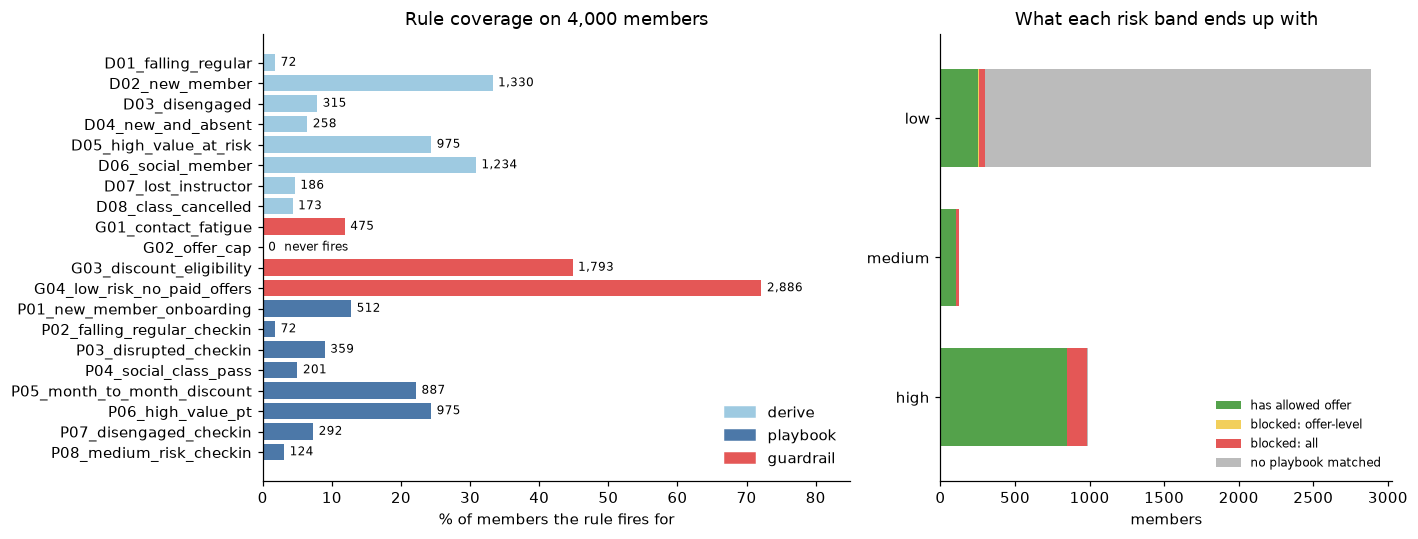

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
colour = {"derive": "#9ecae1", "playbook": "#4c78a8", "guardrail": "#e45756"}
cov = coverage.iloc[::-1]
a.barh(cov.index, cov["share"] * 100, color=[colour[k] for k in cov["kind"]])
for y, (share, m) in enumerate(zip(cov["share"], cov["members"])):
    a.text(share * 100 + 0.8, y, f"{m:,}" if m else "0  never fires", va="center", fontsize=8)
a.set_xlabel("% of members the rule fires for")
a.set_xlim(0, 85)
a.set_title("Rule coverage on 4,000 members")
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colour.values()], labels=colour.keys(), loc="lower right", frameon=False)

order = ["has allowed offer", "blocked: offer-level", "blocked: all", "no playbook matched"]
shade = {"has allowed offer": "#54a24b", "blocked: offer-level": "#f2cf5b", "blocked: all": "#e45756", "no playbook matched": "#bbbbbb"}
t = by_band.drop(columns="All", index="All").reindex(columns=order, fill_value=0)
t.plot.barh(stacked=True, ax=b, color=[shade[c] for c in t.columns], width=0.7)
b.set_xlabel("members")
b.set_ylabel("")
b.set_title("What each risk band ends up with")
b.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e6_rule_coverage.png", bbox_inches="tight")

## 4. Plan value with vs without guardrails

How much expected retention (scenario ground truth `true_uplift`, E4's metric) does a plan gain or lose when the
guardrails are removed from the candidate set? Candidates **with** guardrails are `RuleOutcome.allowed` from the run above;
candidates **without** are `free[m].allowed` (guardrails off), same members. Both are scored on `true_uplift` at several
budgets and 5 seeds, with a fixed weekly staff-minute limit. We also count the **violations** the guardrail-free plan makes
(each selected offer a guardrail would have blocked, by guardrail), since those are what the guardrails exist to prevent.

> **PROVISIONAL.** Until Stream B's optimiser lands, plans are chosen by a greedy stand-in (highest true uplift per dollar
> under the budget and staff-minute limits, one offer per member). It also reads the scenario's true uplift, which no real
> optimiser can see, so it is an upper-bound picker. Numbers from the stand-in are **not the reported
> result**. When `anchorai.optimisation` lands, change the single line `select = greedy_plan` (two cells down) to B's
> function with the same signature `select(candidates, budget, staff_minutes, seed) -> DataFrame`.

"Per dollar" cannot rank free offers (cost 0), so the stand-in ranks by true uplift per unit of combined resource share,
`cost / budget + staff_minutes / staff_limit`.

In [13]:
from anchorai.scenario.tables import read_tables

truth = read_tables()["true_uplift"].set_index(["member_id", "offer_id"])["uplift"]
cost = {o["offer_id"]: o["cost"] for o in OFFER_CATALOG}
minutes = {o["offer_id"]: o["staff_minutes"] for o in OFFER_CATALOG}


def candidate_table(run_outcomes, source):
    rows = []
    for m, o in run_outcomes.items():
        for p in o.allowed:
            blocker = outcomes[m].blocked.get("all") or outcomes[m].blocked.get(p.offer_id) or ""
            rows.append({"member_id": m, "offer_id": p.offer_id, "channel": p.channel})
            rows[-1]["violates"] = blocker if source == "free" else ""
    t = pd.DataFrame(rows)
    t["cost"] = t["offer_id"].map(cost)
    t["staff_minutes"] = t["offer_id"].map(minutes)
    t["true_uplift"] = [truth.get((m, o), 0.0) for m, o in zip(t["member_id"], t["offer_id"])]
    return t


cand_guard = candidate_table(outcomes, "guard")
cand_free = candidate_table(free, "free")
print(len(cand_guard), "candidates with guardrails,", len(cand_free), "without;",
      f"{(cand_free['violates'] != '').sum()} of the latter violate a guardrail")
print("offer costs:", cost, "| total cost of all guarded candidates:", cand_guard["cost"].sum())
cand_free.groupby("offer_id").agg(n=("member_id", "size"), mean_uplift=("true_uplift", "mean"), violating=("violates", lambda s: (s != "").sum())).round(3)

2481 candidates with guardrails, 2894 without; 413 of the latter violate a guardrail
offer costs: {'checkin_message': 0.0, 'free_pt_session': 40.0, 'class_pass': 15.0, 'discount_1m': 12.0} | total cost of all guarded candidates: 45643.0


,n,mean_uplift,violating
offer_id,,,
checkin_message,808,0.047,110
class_pass,201,0.098,24
discount_1m,887,0.097,128
free_pt_session,998,0.227,151


In [14]:
def greedy_plan(candidates, budget, staff_minutes, seed=0):
    """Stand-in for the optimiser: best uplift per unit of resource share, one offer per member, deterministic."""
    c = candidates[candidates["true_uplift"] > 0].copy()
    c["score"] = c["true_uplift"] / (c["cost"] / budget + c["staff_minutes"] / staff_minutes)
    c = c.sort_values(["score", "member_id", "offer_id"], ascending=[False, True, True])
    spent = used = 0.0
    taken, keep = set(), []
    for i, r in zip(c.index, c.itertuples()):
        if r.member_id in taken or spent + r.cost > budget or used + r.staff_minutes > staff_minutes:
            continue
        taken.add(r.member_id)
        spent += r.cost
        used += r.staff_minutes
        keep.append(i)
    return c.loc[keep].drop(columns="score")


select = greedy_plan  # PROVISIONAL stand-in: replace with the anchorai.optimisation function when Stream B lands

In [15]:
BUDGETS = [500, 1000, 2000, 4000]
# A 7,200-minute weekly limit (3 consultants x 40 h). At 3 x 5 h staff time binds first and every budget gives the same plan.
STAFF_MINUTES = 3 * 40 * 60
SEEDS = range(5)

rows, violation_rows = [], []
for budget in BUDGETS:
    for seed in SEEDS:
        for name, cands in [("with guardrails", cand_guard), ("without guardrails", cand_free)]:
            plan = select(cands, budget, STAFF_MINUTES, seed)
            rows.append({"budget": budget, "seed": seed, "plan": name, "offers": len(plan),
                         "retained": plan["true_uplift"].sum(), "spend": plan["cost"].sum(),
                         "staff_minutes": plan["staff_minutes"].sum()})
            if name == "without guardrails":
                for g, n in plan.loc[plan["violates"] != "", "violates"].value_counts().items():
                    violation_rows.append({"budget": budget, "seed": seed, "guardrail": g, "violations": n})

runs = pd.DataFrame(rows)
value = runs.pivot_table(index="budget", columns="plan", values="retained", aggfunc=["mean", "std"])
value.columns = [f"{'retained' if a == 'mean' else 'sd'} {b}" for a, b in value.columns]
value["gap (free - guarded)"] = value["retained without guardrails"] - value["retained with guardrails"]
spend = runs.pivot_table(index="budget", columns="plan", values=["offers", "spend", "staff_minutes"], aggfunc="mean")
spend.columns = [f"{a} {b}" for a, b in spend.columns]
violations = (pd.DataFrame(violation_rows, columns=["budget", "seed", "guardrail", "violations"])
              .groupby(["budget", "guardrail"])["violations"].mean().unstack(fill_value=0).reindex(BUDGETS, fill_value=0))
violations["total"] = violations.sum(axis=1)
violations["share of free plan offers"] = violations["total"] / spend["offers without guardrails"]

plan_value = value.join(spend).join(violations.add_prefix("violations "))
plan_value.round(3).to_csv(RES / "e6_plan_value.csv")
plan_value.round(2).T

budget,500,1000,2000,4000
retained with guardrails,40.66,47.70,59.79,73.97
retained without guardrails,45.60,52.60,65.19,80.02
sd with guardrails,0.00,0.00,0.00,0.00
sd without guardrails,0.00,0.00,0.00,0.00
gap (free - guarded),4.93,4.91,5.40,6.05
offers with guardrails,739.00,781.00,862.00,911.00
offers without guardrails,849.00,890.00,972.00,879.00
spend with guardrails,492.00,999.00,1992.00,3399.00
spend without guardrails,492.00,990.00,1998.00,3627.00
staff_minutes with guardrails,4105.00,4730.00,5910.00,7200.00


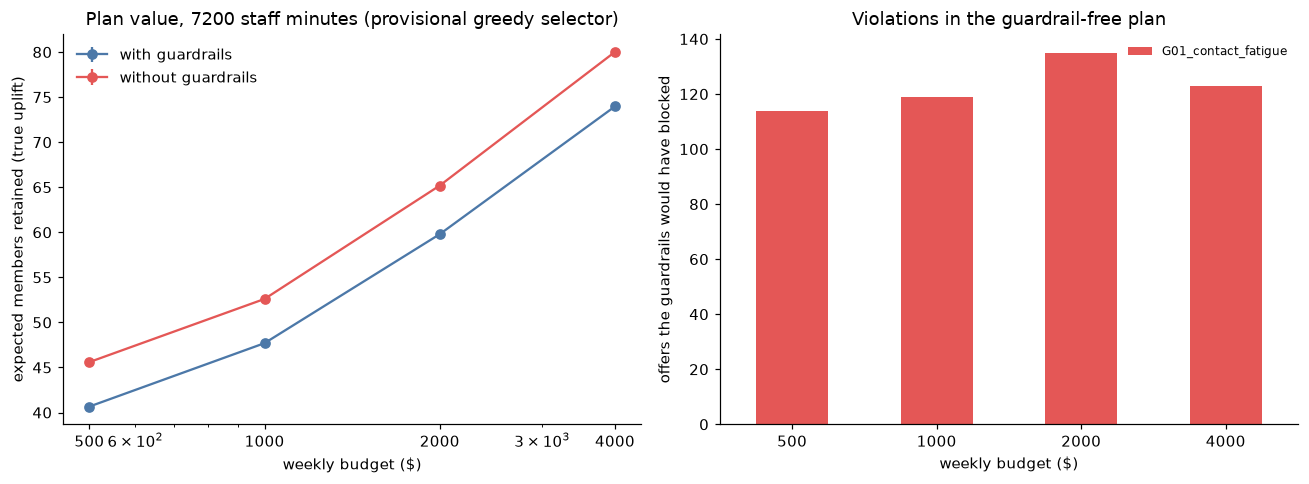

In [16]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, colour in [("with guardrails", "#4c78a8"), ("without guardrails", "#e45756")]:
    a.errorbar(value.index, value[f"retained {name}"], yerr=value[f"sd {name}"].fillna(0), marker="o", color=colour, label=name)
a.set_xscale("log")
a.set_xticks(BUDGETS, [str(x) for x in BUDGETS])
a.set_xlabel("weekly budget ($)")
a.set_ylabel("expected members retained (true uplift)")
a.set_title(f"Plan value, {STAFF_MINUTES} staff minutes (provisional greedy selector)")
a.legend(frameon=False)

v = violations.drop(columns=["total", "share of free plan offers"])
v.plot.bar(stacked=True, ax=b, color={"G01_contact_fatigue": "#e45756", "G04_low_risk_no_paid_offers": "#f2cf5b"}, rot=0)
b.set_xlabel("weekly budget ($)")
b.set_ylabel("offers the guardrails would have blocked")
b.set_title("Violations in the guardrail-free plan")
b.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e6_plan_value.png", bbox_inches="tight")

**Look for:**

- The guardrail-free plan should retain **at least as many** as the guarded one (it has a superset of candidates). If it
  retains fewer, the selector is not optimal (greedy is not), say so rather than reading it as "guardrails help".
- The finding is the **cost of the guardrails** (the gap column) set against **what they prevent** (violations: contacts
  inside 30 days, paid offers to low-risk members). A small gap with many violations supports keeping the guardrails.
- Whether the staff-minute limit, not the budget, is the binding constraint (compare `spend` and `staff_minutes` columns
  across budgets). If it is, the budgets barely matter and the gap is flat.
- The stand-in is deterministic, so the 5 seeds give identical rows (sd 0). B's GA will vary by seed.

## 5. Findings

From the run on 2026-10-16, after the rule changes from the simulated interviews (D01 at 0.7, D03 relative to the
member's usual rate, new D04 for absent new members, P02 a check-in, P05 later in the order, P08 by SMS).

1. **Validator and cases.** 0 validator issues; 25 of 25 scenario cases match the shipped rules.
2. **`G02_offer_cap` never fires** on the 4,000 members: `offers_last_90d` is 0 or 1 for everyone in the scenario layer, so
   the cap of 2 is unreachable. It is data, not a bug: the simulator never contacts a member twice in 90 days. State it
   in the report; it also means G02 is untested on real data (the scenario cases do exercise it).
3. **`G03_discount_eligibility` never removes a proposal.** Its only proposer, P05, already requires
   `contract_period == 1`, so G03 matches 1,793 members but blocks nothing the playbooks propose. It is a safety net for
   manual plan overrides (HANDOFFS #12) and future playbooks, not a working guardrail today.
4. **What guardrails actually do:** of 3,422 proposals, 483 (14.1%) are removed: 473 by `G01_contact_fatigue`
   (197 members) and 10 by `G04_low_risk_no_paid_offers`. 144 of 990 high-risk members end with no allowed offer, 140
   because of contact fatigue.
5. **70% of members have no allowed offer**, but 2,590 of those are low-risk members that no playbook targets (by design).
   Only 4 high-risk members have no playbook at all.
6. **Medium risk is a thin band** (124 members, 3.1%), so P04, P07 and P08 mostly act on high-risk members.
7. **No opt-out fact** exists, so "never contact opted-out members" cannot be expressed (see part 2). Decided: out
   of scope, stated in the report.
8. **Low-risk new-and-slipping members** (P01) are proposed a PT session and then blocked by G04 (10 cases; P02 now
   proposes a free check-in, which G04 allows). Decided:
   **keep G04 as is.** The churn model already weighs tenure heavily (months as a member is a top driver), so a new
   member it still scores low risk is not worth a paid session. G04 blocks only paid offers, so free contacts are
   unaffected, and the blocked proposals stay visible in the trace so staff can see the choice.
9. **With vs without guardrails (counts):** switching the guardrails off gives 1,406 members an offer instead of 1,202,
   and 2,894 offers instead of 2,481. The 413 extra offers (14.3%) are 403 contacts inside 30 days of the last one (G01)
   and 10 paid offers to low-risk members (G04). Whether removing them costs retention is part 4.
10. **Plan value (part 4)** uses a provisional greedy selector until Stream B's optimiser lands, so its numbers are not a
    reported result. With it, removing the guardrails retains 4.9-6.1 more expected members (8-12%) at budgets of
    $500-$4,000, at the cost of 114-135 contacts inside 30 days of the last one (13-14% of the guardrail-free plan). The
    guardrails cost some retention; what they prevent is contacting members inside the 30-day limit.
11. **Rule changes from the interviews:** D01 now covers 72 members (was 127), D03 315 (was 502; members who always came
    rarely are no longer flagged) and the new D04 258 new members who are barely visiting. P07 reaches 292 members.
